# Horas de trabajo perdidas por bajas médicas

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "horas-perdidas-incapacidad-temporal"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Horas de trabajo perdidas por bajas médicas"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de las horas pactadas"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Las horas que no se trabajan por incapacidad temporal (bajas médicas por enfermedad o accidente) en porcentaje de las horas pactadas, por trabajador y mes, en el conjunto de la industria, la construcción y los servicios.

**Cómo se lee.** Si el valor es 4, de cada 100 horas de trabajo pactadas, 4 no se trabajan porque la persona está de baja. Las horas se reparten entre todos los asalariados, estén o no de baja.

**Limitaciones.**
- **Asalariados:** la Encuesta Trimestral de Coste Laboral (ETCL) del INE cubre las cuentas de cotización del Régimen General de la Seguridad Social (secciones B a S de la CNAE-2009) y del Régimen Especial de Trabajadores del Mar; no incluye a los autónomos ni la agricultura.
- **Horas pactadas:** incluyen las de vacaciones y fiestas, así que el porcentaje sería mayor sobre las horas que se trabajan.
- **Causa de la baja:** la encuesta recoge los días de baja por incapacidad temporal sin distinguir si son por enfermedad común, accidente no laboral o contingencia profesional.
- **Solo España:** no hay un indicador equivalente en las fuentes internacionales autorizadas.

## 2. Descarga

INE, ETCL, tiempo de trabajo por trabajador y mes, total de industria, construcción y servicios y de los dos tipos de jornada, datos trimestrales:

- **Desde 2008:** tabla 6044 (CNAE-2009): horas no trabajadas por incapacidad temporal (`ETCL2401`) y horas pactadas (`ETCL2409`).
- **De 2000 a 2007:** tabla 6080, series retrospectivas que el INE calcula con la CNAE-2009 (`ETCL7138` y `ETCL7146`).

La media anual de los cuatro trimestres la calcula `lib.ine.get` (descarta el año en curso si está incompleto).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos, ine
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

SERIES = {
    "ETCL2401": "it", "ETCL2409": "pactadas",  # tabla 6044, desde 2008
    "ETCL7138": "it_retro", "ETCL7146": "pactadas_retro",  # tabla 6080, retrospectivas
}
crudo, fuentes_ine = ine.get(SERIES, agregacion="media", desde=DESDE)
display(crudo.pivot(index="periodo", columns="serie", values="valor"))

serie,it,it_retro,pactadas,pactadas_retro
periodo,,,,
2000,NaN,4.150,NaN,159.825
2001,NaN,4.375,NaN,159.800
2002,NaN,4.700,NaN,159.650
2003,NaN,4.925,NaN,158.975
2004,NaN,5.225,NaN,158.175
2005,NaN,5.350,NaN,157.650
2006,NaN,5.425,NaN,157.125
2007,NaN,5.475,NaN,156.825
2008,5.100,NaN,156.100,NaN


## 3. Transformación

1. Se unen las retrospectivas (hasta 2007) y la serie actual (desde 2008): son la misma variable con la misma clasificación (CNAE-2009) y no se solapan.
2. Porcentaje: media anual de las horas no trabajadas por incapacidad temporal entre media anual de las horas pactadas, por 100.

In [ ]:
serie = lambda s: crudo[crudo["serie"] == s].set_index("periodo")["valor"]  # noqa: E731
for actual, retro in (("it", "it_retro"), ("pactadas", "pactadas_retro")):
    assert serie(retro).index.max() < serie(actual).index.min(), f"{actual}: las retrospectivas se solapan con la serie actual"
it = pd.concat([serie("it_retro"), serie("it")])
pactadas = pd.concat([serie("pactadas_retro"), serie("pactadas")])
pct = (it / pactadas * 100).dropna()
assert pct.between(0.5, 15).all(), "porcentaje fuera de rango: ¿unidades?"
df = pd.DataFrame({"serie": "espana", "periodo": pct.index, "valor": pct.values})

PRIMER_ANIO, PRIMER_ACTUAL = int(pct.index.min()), int(serie("it").index.min())
HOY = fuentes_ine[0].fecha_consulta
fuentes = [FuenteMeta(
    "espana", ine.ORGANISMO,
    "ETCL, tiempo de trabajo por trabajador y mes: horas no trabajadas por I.T. entre horas pactadas "
    "(tabla 6044: ETCL2401 y ETCL2409; retrospectivas de la tabla 6080: ETCL7138 y ETCL7146)",
    "https://www.ine.es/jaxiT3/Tabla.htm?t=6044", HOY,
)]
display(pd.DataFrame({"horas I.T.": it, "horas pactadas": pactadas, "%": pct}).round(2))

,horas I.T.,horas pactadas,%
periodo,,,
2000,4.15,159.82,2.60
2001,4.38,159.80,2.74
2002,4.70,159.65,2.94
2003,4.92,158.98,3.10
2004,5.22,158.18,3.30
2005,5.35,157.65,3.39
2006,5.42,157.12,3.45
2007,5.48,156.83,3.49
2008,5.10,156.10,3.27


### Notas

In [ ]:
NOTAS = [
    "INE, Encuesta Trimestral de Coste Laboral (ETCL): horas no trabajadas por incapacidad temporal entre horas "
    "pactadas, por trabajador y mes, en el total de industria, construcción y servicios y de los dos tipos de jornada; "
    "media anual de los cuatro trimestres de cada componente.",
    f"De {PRIMER_ANIO} a {PRIMER_ACTUAL - 1}, series retrospectivas del INE con la CNAE-2009 (tabla 6080); desde "
    f"{PRIMER_ACTUAL}, la serie actual (tabla 6044). La ETCL empieza en {PRIMER_ANIO}.",
    "Cubre a los asalariados de las cuentas de cotización del Régimen General de la Seguridad Social (secciones B a S "
    "de la CNAE-2009) y del Régimen Especial de Trabajadores del Mar; no incluye a los autónomos ni la agricultura.",
    "Las horas pactadas incluyen las de vacaciones y fiestas. Las horas se reparten entre todos los asalariados, "
    "estén o no de baja, y la encuesta no distingue la causa de la baja (enfermedad o accidente, laboral o no).",
    "Solo España: no hay un indicador equivalente en las fuentes internacionales autorizadas.",
]
for n in NOTAS:
    print("-", n)

- INE, Encuesta Trimestral de Coste Laboral (ETCL): horas no trabajadas por incapacidad temporal entre horas pactadas, por trabajador y mes, en el total de industria, construcción y servicios y de los dos tipos de jornada; media anual de los cuatro trimestres de cada componente.
- De 2000 a 2007, series retrospectivas del INE con la CNAE-2009 (tabla 6080); desde 2008, la serie actual (tabla 6044). La ETCL empieza en 2000.
- Cubre a los asalariados de las cuentas de cotización del Régimen General de la Seguridad Social (secciones B a S de la CNAE-2009) y del Régimen Especial de Trabajadores del Mar; no incluye a los autónomos ni la agricultura.
- Las horas pactadas incluyen las de vacaciones y fiestas. Las horas se reparten entre todos los asalariados, estén o no de baja, y la encuesta no distingue la causa de la baja (enfermedad o accidente, laboral o no).
- Solo España: no hay un indicador equivalente en las fuentes internacionales autorizadas.


## 4. Visualización

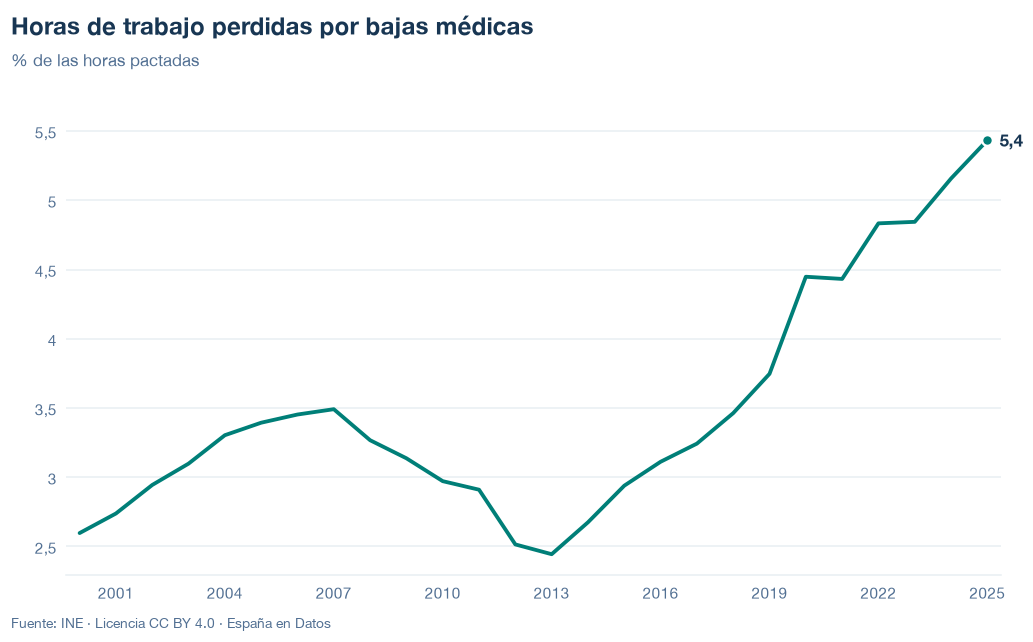

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/horas-perdidas-incapacidad-temporal.json y data/horas-perdidas-incapacidad-temporal.csv


## 6. Fuentes, notas y licencia

- INE, Encuesta Trimestral de Coste Laboral, tiempo de trabajo por trabajador y mes: tablas 6044 (desde 2008) y 6080 (series retrospectivas, 2000-2007). Metodología: https://www.ine.es/metodologia/t22/t2230187.pdf

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.